# 01. Data Preprocessing & Physics Defect Criteria

**Paper**: *AdditiveLLM: Large language models predict defects in metals additive manufacturing*  
**Authors**: Peter Pak & Amir Barati Farimani (CMU, 2025)  
**Publication**: *Additive Manufacturing Letters 14 (2025) 100292* | [arXiv:2501.17784](https://arxiv.org/abs/2501.17784)

### Notebook Purpose
This notebook implements and validates the exact data preprocessing pipeline, physical defect boundary equations, and text formatting methods introduced in the paper:
1. **Equation 1**: Lack of Fusion Porosity criterion (geometry overlap threshold)
2. **Equation 2**: Balling Porosity criterion (Plateau-Rayleigh capillary instability)
3. **Equation 3**: Keyhole Porosity criterion (melt pool aspect ratio threshold)
4. Multi-label encoding across 4 defect regimes (`None / Desirable`, `Keyhole`, `Lack of Fusion`, `Balling`)
5. Structured Baseline `[SEP]` formatting and Natural Language Prompt formatting
6. Preliminary inspection of class balances and data leakage across splits.

In [1]:
import os
import sys
import math
import ast
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
print('Environment initialized successfully.')

Environment initialized successfully.


## 1. Physics-Based Defect Criteria Formulation

The paper classifies Laser Powder Bed Fusion (L-PBF) melt pools into 4 defect regimes based on physical thresholds:

### Equation 1: Lack of Fusion (LOF) Porosity
Insufficient overlap between adjacent scan tracks or successive layers leads to un-melted powder particles:
$$\left(\frac{h}{w}\right)^2 + \left(\frac{t}{d}\right)^2 > 1$$
where:
- $h$: Hatch spacing ($\mu$m)
- $t$: Layer thickness / height ($\mu$m)
- $w$: Melt pool width ($\mu$m)
- $d$: Melt pool depth ($\mu$m)

### Equation 2: Balling Porosity
High scan speeds induce Plateau-Rayleigh capillary instability in the liquid cylinder when the melt pool length exceeds its circumference:
$$\frac{l}{w} \ge \pi \approx 3.14159$$
where:
- $l$: Melt pool length ($\mu$m)
- $w$: Melt pool width ($\mu$m)

### Equation 3: Keyhole Porosity
Excessive laser energy density causes recoil pressure and metal vaporization, opening a deep, narrow cavity prone to pore collapse:
$$\frac{w}{d} \le 1.5$$
where:
- $w$: Melt pool width ($\mu$m)
- $d$: Melt pool depth ($\mu$m)

### Regime 0: None / Desirable
When none of the three defect conditions are triggered, the regime is classified as `None` (conduction mode printing).

In [2]:
def evaluate_physics_defects(width, depth, length, hatch_spacing, layer_height):
    """
    Evaluates multi-label defect regimes from melt pool geometry and process parameters.
    Returns: dict of boolean flags and active defect names.
    """
    # Eq. 1: Lack of Fusion
    lof = ((hatch_spacing / width) ** 2 + (layer_height / depth) ** 2) > 1.0
    
    # Eq. 2: Balling
    balling = (length / width) >= math.pi
    
    # Eq. 3: Keyhole
    keyhole = (width / depth) <= 1.5
    
    # None / Desirable
    none_defect = not (keyhole or lof or balling)
    
    defects = []
    if none_defect: defects.append('None')
    if keyhole: defects.append('Keyhole')
    if lof: defects.append('Lack of Fusion')
    if balling: defects.append('Balling')
    
    return {
        'binary_vector': [int(none_defect), int(keyhole), int(lof), int(balling)],
        'defects': defects
    }

# Unit test demonstrations
cases = [
    {'name': 'Desirable', 'w': 120, 'd': 60, 'l': 250, 'h': 100, 't': 30},
    {'name': 'Keyhole', 'w': 110, 'd': 150, 'l': 220, 'h': 80, 't': 30},
    {'name': 'Lack of Fusion', 'w': 90, 'd': 40, 'l': 200, 'h': 180, 't': 80},
    {'name': 'Balling', 'w': 60, 'd': 45, 'l': 250, 'h': 100, 't': 40},
]
for c in cases:
    res = evaluate_physics_defects(c['w'], c['d'], c['l'], c['h'], c['t'])
    print(f"{c['name']:<18}: Vector={res['binary_vector']} -> {', '.join(res['defects'])}")

Desirable         : Vector=[1, 0, 0, 0] -> None
Keyhole           : Vector=[0, 1, 0, 0] -> Keyhole
Lack of Fusion    : Vector=[0, 0, 1, 0] -> Lack of Fusion
Balling           : Vector=[0, 1, 1, 1] -> Keyhole, Lack of Fusion, Balling


## 2. Dataset Inspection & Split Loading

We inspect the official parquets downloaded from `ppak10/melt-pool-classification`.

In [3]:
val_df = pd.read_parquet('../data/splits/validation_baseline.parquet')
print(f'Validation Baseline Split: {len(val_df):,} rows')
print('Columns:', val_df.columns.tolist())
val_df.head(5)

Validation Baseline Split: 72,475 rows
Columns: ['id', 'label', 'text']


,id,label,text
0,1,"[0, 1, 1, 1]",IN718[SEP]200.0 W[SEP]600.0 mm/s[SEP]100.0 mic...
1,2,"[0, 1, 1, 1]",SS316L[SEP]45.0 W[SEP]900.0 mm/s[SEP][SEP][SEP]
2,3,"[0, 1, 1, 1]",SS316L[SEP]45.0 W[SEP]2900.0 mm/s[SEP][SEP][SEP]
3,4,"[0, 1, 1, 1]",SS316L[SEP]45.0 W[SEP]3400.0 mm/s[SEP][SEP][SEP]
4,5,"[0, 1, 1, 1]",SS304L[SEP]45.0 W[SEP]2400.0 mm/s[SEP][SEP][SEP]


## 3. Defect Class Distributions (Figure 6 Reproduction)

We compute positive frequencies for each defect class across the validation set.

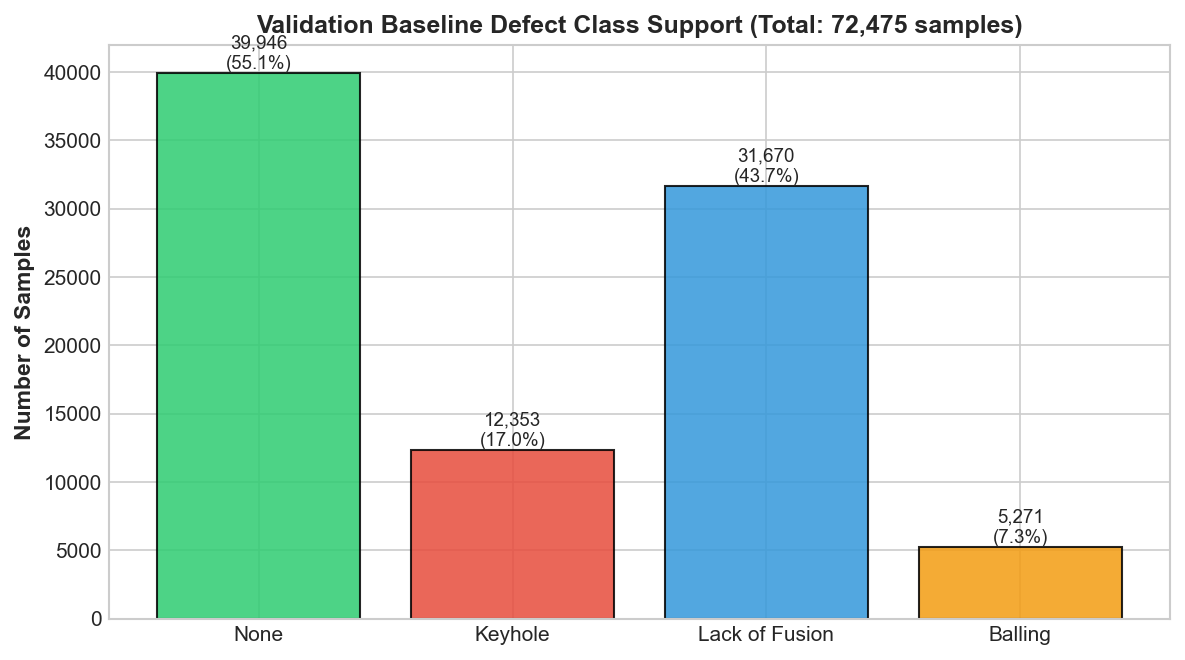

In [4]:
labels = np.array([ast.literal_eval(l) if isinstance(l, str) else l for l in val_df['label']], dtype=np.int32)
class_names = ['None', 'Keyhole', 'Lack of Fusion', 'Balling']
counts = labels.sum(axis=0)
percentages = counts / len(labels) * 100

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
bars = ax.bar(class_names, counts, color=['#2ecc71', '#e74c3c', '#3498db', '#f39c12'], edgecolor='black', alpha=0.85)
ax.set_ylabel('Number of Samples', fontsize=11, fontweight='bold')
ax.set_title('Validation Baseline Defect Class Support (Total: 72,475 samples)', fontsize=12, fontweight='bold')
for b in bars:
    h = b.get_height()
    ax.annotate(f'{h:,}\n({h/len(labels)*100:.1f}%)', (b.get_x() + b.get_width()/2., h), ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 4. Text Formatting Comparison: Baseline vs. Prompt

The paper explores two representations of process parameters:
1. **Baseline**: Delimited string `<Material>[SEP]<Power>[SEP]<Velocity>[SEP]<BeamDiameter>[SEP]<HatchSpacing>[SEP]<LayerHeight>`
2. **Prompt**: Natural language query populated from template variations.

In [5]:
sample_baseline = val_df['text'].iloc[0]
print('Sample Baseline Input:')
print(sample_baseline)

prompt_df = pd.read_parquet('../data/splits/validation_prompt.parquet')
sample_prompt = prompt_df['text'].iloc[0]
print('\nSample Prompt Input:')
print(sample_prompt)

Sample Baseline Input:
IN718[SEP]200.0 W[SEP]600.0 mm/s[SEP]100.0 microns[SEP]500.0 microns[SEP]70.0 microns

Sample Prompt Input:
What defects would occur in IN718 L-PBF produced melt pools at 200.0 W, using a 100.0 microns beam diameter, 600.0 mm/s scan speed, 500.0 microns hatch spacing, and a 70.0 microns layer height?
